# 이야기담 — v2 재학습(수정판) + v1 vs v2 성능 비교
**순서대로 실행.** 런타임: GPU (L4/A100, 배치 256 = v1과 동일).

- v1 = 기존 모델 (`deploy/rtmpose-m_drawing15_ep30.pth`, 30에폭, test AP 0.919)
- v2 = v1(ep30)에서 이어서, train+val(약 168k장)로 12에폭 재파인튜닝 (lr 3e-4 @ 배치 256, 배치에 비례해 조정)
- test 8,908장은 **v1과 동일 split(seed 42)** 으로 학습에서 완전히 제외 → 공정 비교

**이전 버전에서 고친 점**
1. config 수정을 정규식 → mmengine `Config` API로 변경. `deploy/drawing15_full.py`는 mmengine이 값을 풀어서 저장한 파일이라, 맨 위 `base_lr`/`max_epochs`만 바꾸면 실제 학습(lr=0.001, 30에폭 스케줄, stage2 25에폭)에는 반영되지 않았음. 이제 실제로 쓰이는 필드(`optimizer.lr`, `train_cfg.max_epochs`, `param_scheduler`, `PipelineSwitchHook.switch_epoch`)를 직접 바꾸고 저장 후 다시 읽어 assert로 검증.
2. 새 work_dir(`drawing15_v2b`) 사용. 기존 `drawing15_v2`에서 `--resume`하면 잘못된 스케줄러 상태가 다시 로드됨.
3. 첫 실행은 `--resume` 없이 시작. mmpose `train.py`는 `--resume`을 주면 `load_from`을 None으로 지우기 때문에, 체크포인트가 없는 첫 실행에 `--resume`을 붙이면 v1 가중치를 불러오지 않음. `last_checkpoint`가 있을 때만 `--resume`을 붙이도록 함.
4. 이미지 tar를 디스크에 풀지 않고 스트리밍으로 받으면서 바로 리사이즈 → 원본 이미지 용량(약 48GB)이 디스크에 안 올라감.
5. 경로·변수(`W`, `LOG`, `V2_CFG`)를 맨 위에서 한 번에 정의. 수동 `last_checkpoint` 덮어쓰기, 하드코딩된 test 수치 제거.

## 1. Drive 마운트 + 경로 설정

In [30]:
from google.colab import drive
import os
drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/yiyagidam'
os.makedirs(f'{DRIVE}/work_dirs', exist_ok=True)
CFG_DIR = '/content/mmpose/configs/body_2d_keypoint/rtmpose/coco/'
PY = 'MPLBACKEND=Agg PYTHONUNBUFFERED=1 /usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env python -u'

NAME   = 'drawing15_v2b'                       # 새 실험 이름 (config / work_dir / log 모두 이 이름)
V2_CFG = CFG_DIR + NAME + '.py'
W      = f'{DRIVE}/work_dirs/{NAME}'
LOG    = f'{DRIVE}/train_{NAME}.log'

!nvidia-smi --query-gpu=name,memory.total --format=csv
print('CPU:', os.cpu_count())
!ls {DRIVE}/deploy

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
name, memory.total [MiB]
NVIDIA L4, 23034 MiB
CPU: 12
drawing15_full.py  drawing15.py  rtmpose-m_drawing15_ep30.pth


## 2. conda 환경 + mmpose 설치 (~10분)
마지막 줄에 `CUDA True | mmpose import OK`가 찍혀야 함.

In [2]:
%cd /content
!wget -q -nc https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh
!test -d /usr/local/miniconda || bash Miniconda3-latest-Linux-x86_64.sh -b -p /usr/local/miniconda > /dev/null
!/usr/local/miniconda/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/main
!/usr/local/miniconda/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/r
!test -d /usr/local/miniconda/envs/mmpose_env || /usr/local/miniconda/bin/conda create -n mmpose_env python=3.10 -y -q

E = "/usr/local/miniconda/bin/conda run -n mmpose_env"
!{E} pip install -q torch==2.1.2 torchvision==0.16.2 --index-url https://download.pytorch.org/whl/cu121
!{E} pip install -q "numpy<2" "opencv-python<5"
!{E} pip install -q -U openmim
!{E} mim install -q mmengine "mmcv==2.1.0" "mmdet>=3.1.0"
!test -d mmpose || git clone -q https://github.com/open-mmlab/mmpose.git
!{E} pip install -q "numpy<2" chumpy --no-build-isolation
!{E} bash -c "cd /content/mmpose && pip install -q -e ."
!{E} pip install -q "albumentations==1.3.1" future tensorboard
!{E} pip install -q "numpy<2" "opencv-python<5" "opencv-python-headless<5"
!cd / && MPLBACKEND=Agg /usr/local/miniconda/bin/conda run -n mmpose_env python -c "import torch; from mmpose.apis import init_model; print('CUDA', torch.cuda.is_available(), '| mmpose import OK')"

# 설치 캐시 정리 (학습 결과에 영향 없음, 수 GB 확보)
!/usr/local/miniconda/bin/conda clean -a -y -q
!{E} pip cache purge
!rm -f /content/Miniconda3-latest-Linux-x86_64.sh
!df -h /content

/content
accepted Terms of Service for https://repo.anaconda.com/pkgs/main
accepted Terms of Service for https://repo.anaconda.com/pkgs/r
Jupyter detected...
2 channel Terms of Service accepted
Retrieving notices: ...working... done
Channels:
 - defaults
Platform: linux-64
Solving environment: ...working... done

## Package Plan ##

  environment location: /usr/local/miniconda/envs/mmpose_env

  added / updated specs:
    - python=3.10


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    libnsl-2.0.0               |       h5eee18b_0          31 KB
    packaging-26.3             |  py310h06a4308_0         329 KB
    pip-26.2.2                 |     pyhc872135_0         1.1 MB
    python-3.10.22             |       hd9cb797_0        24.4 MB
    setuptools-84.0.0          |  py310h06a4308_0         968 KB
    tk-8.6.15                  |       h54e0aa7_0         3.4 MB
    wheel-0.48.0        

## 3. 라벨 + pretrained 다운로드 (이미지는 §5에서 받음)
이미지 tar(약 48GB)는 디스크에 풀지 않고 §5에서 스트리밍으로 받으면서 바로 리사이즈한다.

In [3]:
%cd /content
!wget -q -nc https://dl.fbaipublicfiles.com/amateur_drawings/amateur_drawings_annotations.json
!wget -q -nc https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/rtmpose-m_simcc-coco_pt-aic-coco_420e-256x192-d8dd5ca4_20230127.pth -O rtmpose-m_coco-256x192.pth
!df -h /content

/content
Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   50G   64G  44% /


## 4. 17→15 joint 변환 + 이미지 단위 split (**v1 split_ids.json을 그대로 불러옴**)

In [4]:
import json, random
import numpy as np

COCO_IDX = {n: i for i, n in enumerate([
    "nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle"])}
J15 = ["nose", "neck", "right_shoulder", "right_elbow", "right_wrist",
       "left_shoulder", "left_elbow", "left_wrist", "pelvis",
       "right_hip", "right_knee", "right_ankle", "left_hip", "left_knee", "left_ankle"]
SKEL_1BASED = [[a + 1, b + 1] for a, b in [(0,1),(1,2),(2,3),(3,4),(1,5),(5,6),(6,7),
                                           (1,8),(8,9),(9,10),(10,11),(8,12),(12,13),(13,14)]]

def to15(k17):
    k = np.array(k17, dtype=np.float32).reshape(17, 3)
    g = lambda n: k[COCO_IDX[n]]
    mid = lambda a, b: np.array([(g(a)[0]+g(b)[0])/2, (g(a)[1]+g(b)[1])/2, min(g(a)[2], g(b)[2])])
    return np.stack([g("nose"), mid("left_shoulder", "right_shoulder"),
                     g("right_shoulder"), g("right_elbow"), g("right_wrist"),
                     g("left_shoulder"), g("left_elbow"), g("left_wrist"),
                     mid("left_hip", "right_hip"),
                     g("right_hip"), g("right_knee"), g("right_ankle"),
                     g("left_hip"), g("left_knee"), g("left_ankle")])

raw = json.load(open('/content/amateur_drawings_annotations.json'))
anns = []
for a in raw['annotations']:
    if a.get('num_keypoints', 0) == 0:
        continue
    k = to15(a['keypoints'])
    if (k[:, 2] > 0).sum() < 8:
        continue
    anns.append(dict(id=a['id'], image_id=a['image_id'], bbox=a['bbox'], kpts=k.tolist()))
img_by_id = {im['id']: im for im in raw['images']}
print('annotations:', len(anns))

# v1 때 저장해 둔 split을 그대로 불러온다 (test 8,908장 동일 보장)
SPLIT = {k: set(v) for k, v in json.load(open(f'{DRIVE}/split_ids.json')).items()}
assert not (SPLIT['train'] & SPLIT['val']) and not (SPLIT['train'] & SPLIT['test']) and not (SPLIT['val'] & SPLIT['test'])
valid_ids = {a['image_id'] for a in anns}
for _k in ['train', 'val', 'test']:
    print(_k, '어노테이션 없는 id:', len(SPLIT[_k] - valid_ids))   # 0이어야 정상
print({k: len(v) for k, v in SPLIT.items()})

annotations: 178166
train 어노테이션 없는 id: 0
val 어노테이션 없는 id: 0
test 어노테이션 없는 id: 0
{'test': 8908, 'val': 8908, 'train': 160350, 'smoke_train': 3000, 'smoke_val': 500}


## 5. 이미지 스트리밍 다운로드 → 바로 리사이즈(긴 변 ≤1024, JPEG) + COCO json 생성 (20~40분)
원본 이미지를 디스크에 저장하지 않는다. tar를 받으면서 한 장씩 꺼내 메모리에서 리사이즈한 뒤 `data_small`에만 저장 → 디스크 최대 사용량 = `data_small` 크기.
리사이즈 방식(BILINEAR, quality 95, 좌표 스케일)은 v1과 완전히 동일.
중간에 끊기면 이 셀을 다시 실행: `_info.jsonl`에 기록된 이미지는 건너뛴다(다운로드는 처음부터 다시 흘러가지만 디스크는 안 늘어남).

In [7]:
import os, io, json, tarfile, subprocess
from PIL import Image
from concurrent.futures import ProcessPoolExecutor, wait, FIRST_COMPLETED

URL = 'https://dl.fbaipublicfiles.com/amateur_drawings/amateur_drawings.tar'
DST, MAX = '/content/data_small/', 1024
INFO_PATH = DST + '_info.jsonl'
used = set().union(*[SPLIT[s] for s in ['train', 'val', 'test']])
id_by_name = {img_by_id[i]['file_name']: i for i in used}

def proc_bytes(iid, fn0, data):           # v1의 proc()와 같은 처리, 입력만 파일 대신 bytes
    fn = os.path.splitext(fn0)[0] + '.jpg'
    img = Image.open(io.BytesIO(data))
    w, h = img.size
    s = min(1.0, MAX / max(w, h))
    os.makedirs(os.path.dirname(DST + fn), exist_ok=True)
    img = img.convert('RGB')
    if s < 1.0:
        img = img.resize((round(w * s), round(h * s)), Image.BILINEAR)
    img.save(DST + fn, quality=95)
    return iid, (fn, s, round(w * s), round(h * s))

# 이전에 처리한 것 불러오기 (재실행 대비)
os.makedirs(DST, exist_ok=True)
INFO = {}
if os.path.exists(INFO_PATH):
    for l in open(INFO_PATH):
        try:
            iid, v = json.loads(l); INFO[iid] = tuple(v)
        except json.JSONDecodeError:
            pass                           # 끊길 때 반쯤 쓴 마지막 줄은 무시
todo = used - set(INFO)
print(f'이미 처리 {len(INFO)} / 남음 {len(todo)}')

if todo:
    wget = subprocess.Popen(['wget', '-q', '-O', '-', URL], stdout=subprocess.PIPE)
    seen = matched = 0
    with ProcessPoolExecutor(os.cpu_count()) as ex, \
         tarfile.open(fileobj=wget.stdout, mode='r|*') as tar, \
         open(INFO_PATH, 'a') as log:
        pending = set()
        def collect(fs):
            for f in fs:
                iid, v = f.result()
                INFO[iid] = v
                log.write(json.dumps([iid, v]) + '\n')
        for m in tar:
            if not m.isfile():
                continue
            seen += 1
            name = m.name[2:] if m.name.startswith('./') else m.name
            iid = id_by_name.get(name)
            if seen == 2000 and matched == 0:
                raise RuntimeError(f'tar 경로와 file_name이 안 맞음. 예: tar={name!r} / json={next(iter(id_by_name))!r}')
            if iid is None or iid not in todo:
                continue
            matched += 1
            pending.add(ex.submit(proc_bytes, iid, name, tar.extractfile(m).read()))
            if len(pending) >= 256:        # 메모리에 쌓이는 이미지 수 제한
                done, pending = wait(pending, return_when=FIRST_COMPLETED)
                collect(done)
            if matched % 10000 == 0:
                log.flush()
                print(f'{len(INFO)} / {len(used)}', flush=True)
        collect(wait(pending)[0])
    wget.wait()

missing = used - set(INFO)
assert not missing, f'{len(missing)}장 누락 (다운로드가 중간에 끊겼으면 이 셀 재실행)'
print('resized:', len(INFO))
!du -sh {DST}; df -h /content

def write_coco(split, dst):
    ids = SPLIT[split]
    out_anns = []
    for a in anns:
        if a['image_id'] not in ids:
            continue
        s = INFO[a['image_id']][1]
        flat, nv = [], 0
        for x, y, v in a['kpts']:
            flat += [x * s, y * s, int(v)]
            nv += int(v > 0)
        bx = [v * s for v in a['bbox']]
        out_anns.append(dict(id=a['id'], image_id=a['image_id'], category_id=1, bbox=bx,
                             area=bx[2] * bx[3], iscrowd=0, keypoints=flat, num_keypoints=nv))
    imgs = [dict(id=i, file_name=INFO[i][0], width=INFO[i][2], height=INFO[i][3]) for i in ids]
    json.dump(dict(images=imgs, annotations=out_anns,
                   categories=[dict(id=1, name='human', supercategory='drawing',
                                    keypoints=J15, skeleton=SKEL_1BASED)]), open(dst, 'w'))
    print(f'{dst}: images {len(imgs)} / anns {len(out_anns)}')

for sp in SPLIT:
    write_coco(sp, f'/content/{sp}_coco.json')

이미 처리 178166 / 남음 0
resized: 178166
9.7G	/content/data_small/
Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   59G   54G  53% /
/content/test_coco.json: images 8908 / anns 8908
/content/val_coco.json: images 8908 / anns 8908
/content/train_coco.json: images 160350 / anns 160350
/content/smoke_train_coco.json: images 3000 / anns 3000
/content/smoke_val_coco.json: images 500 / anns 500


In [6]:
from collections import Counter
print('wget 종료코드:', wget.returncode)
cnt = Counter(img_by_id[i]['file_name'] for i in used)
print('누락', len(missing), '| 그 중 file_name 중복', sum(cnt[img_by_id[i]['file_name']] > 1 for i in missing))
print('non-ascii 이름:', sum(not img_by_id[i]['file_name'].isascii() for i in missing))
print(sorted(img_by_id[i]['file_name'] for i in missing)[:8])

# 같은 파일을 가리키는 id는 이미 처리된 결과를 그대로 복사 (같은 파일 → 같은 결과)
by_name = {}
for i in INFO:
    by_name.setdefault(img_by_id[i]['file_name'], INFO[i])
fixed = 0
with open(INFO_PATH, 'a') as log:
    for i in missing:
        v = by_name.get(img_by_id[i]['file_name'])
        if v:
            INFO[i] = tuple(v); log.write(json.dumps([i, v]) + '\n'); fixed += 1
print('복구', fixed, '/ 남은 누락', len(used - set(INFO)))

wget 종료코드: 0
누락 443 | 그 중 file_name 중복 443
non-ascii 이름: 0
['amateur_drawings/0/000192a00d884308afb27a90951d21bd.png', 'amateur_drawings/0/00086c600b394fe9965aebd7a0a00f7e.png', 'amateur_drawings/0/000c72abde7143b7a9151b6074282ebc.png', 'amateur_drawings/0/000fb2de9c024294aa4578306b280c0a.png', 'amateur_drawings/0/000ff20bf4954a45b2e2fb99949e4cbb.png', 'amateur_drawings/0/0010834a520d44548e3fa94e2137b043.png', 'amateur_drawings/0/0010a3b549634cdfb9b50f8a9db44b9a.png', 'amateur_drawings/0/0011731753564803ba0e3a9d0427418a.png']
복구 443 / 남은 누락 0


## 6. dataset_info + v1 config 복원

In [8]:
%%writefile /content/mmpose/configs/_base_/datasets/drawing15.py
dataset_info = dict(
    dataset_name='drawing15',
    paper_info=dict(),
    keypoint_info={
        0: dict(name='nose', id=0, color=[255, 128, 0], type='upper', swap='', sigma=0.026),
        1: dict(name='neck', id=1, color=[255, 128, 0], type='upper', swap='', sigma=0.079),
        2: dict(name='right_shoulder', id=2, color=[255, 128, 0], type='upper', swap='left_shoulder', sigma=0.079),
        3: dict(name='right_elbow', id=3, color=[255, 128, 0], type='upper', swap='left_elbow', sigma=0.072),
        4: dict(name='right_wrist', id=4, color=[255, 128, 0], type='upper', swap='left_wrist', sigma=0.062),
        5: dict(name='left_shoulder', id=5, color=[0, 255, 0], type='upper', swap='right_shoulder', sigma=0.079),
        6: dict(name='left_elbow', id=6, color=[0, 255, 0], type='upper', swap='right_elbow', sigma=0.072),
        7: dict(name='left_wrist', id=7, color=[0, 255, 0], type='upper', swap='right_wrist', sigma=0.062),
        8: dict(name='pelvis', id=8, color=[255, 128, 0], type='lower', swap='', sigma=0.107),
        9: dict(name='right_hip', id=9, color=[255, 128, 0], type='lower', swap='left_hip', sigma=0.107),
        10: dict(name='right_knee', id=10, color=[255, 128, 0], type='lower', swap='left_knee', sigma=0.087),
        11: dict(name='right_ankle', id=11, color=[255, 128, 0], type='lower', swap='left_ankle', sigma=0.089),
        12: dict(name='left_hip', id=12, color=[0, 255, 0], type='lower', swap='right_hip', sigma=0.107),
        13: dict(name='left_knee', id=13, color=[0, 255, 0], type='lower', swap='right_knee', sigma=0.087),
        14: dict(name='left_ankle', id=14, color=[0, 255, 0], type='lower', swap='right_ankle', sigma=0.089),
    },
    skeleton_info={
        0: dict(link=('nose', 'neck'), id=0, color=[0, 255, 255]),
        1: dict(link=('neck', 'right_shoulder'), id=1, color=[255, 128, 0]),
        2: dict(link=('right_shoulder', 'right_elbow'), id=2, color=[255, 128, 0]),
        3: dict(link=('right_elbow', 'right_wrist'), id=3, color=[255, 128, 0]),
        4: dict(link=('neck', 'left_shoulder'), id=4, color=[0, 255, 0]),
        5: dict(link=('left_shoulder', 'left_elbow'), id=5, color=[0, 255, 0]),
        6: dict(link=('left_elbow', 'left_wrist'), id=6, color=[0, 255, 0]),
        7: dict(link=('neck', 'pelvis'), id=7, color=[0, 255, 255]),
        8: dict(link=('pelvis', 'right_hip'), id=8, color=[255, 128, 0]),
        9: dict(link=('right_hip', 'right_knee'), id=9, color=[255, 128, 0]),
        10: dict(link=('right_knee', 'right_ankle'), id=10, color=[255, 128, 0]),
        11: dict(link=('pelvis', 'left_hip'), id=11, color=[0, 255, 0]),
        12: dict(link=('left_hip', 'left_knee'), id=12, color=[0, 255, 0]),
        13: dict(link=('left_knee', 'left_ankle'), id=13, color=[0, 255, 0]),
    },
    joint_weights=[1.] * 15,
    sigmas=[0.026, 0.079, 0.079, 0.072, 0.062, 0.079, 0.072, 0.062,
            0.107, 0.107, 0.087, 0.089, 0.107, 0.087, 0.089])

Writing /content/mmpose/configs/_base_/datasets/drawing15.py


In [9]:
import shutil, os
D = f'{DRIVE}/deploy'
assert os.path.exists(f'{D}/rtmpose-m_drawing15_ep30.pth'), 'v1 체크포인트 없음'
shutil.copy(f'{D}/drawing15_full.py', CFG_DIR + 'drawing15_full.py')   # v1 config
print(os.listdir(CFG_DIR)[:5], '...')

['drawing15_full.py', 'rtmpose-t_8xb256-420e_aic-coco-256x192.py', 'rtmpose-m_8xb256-420e_aic-coco-384x288.py', 'rtmpose-s_8xb256-420e_aic-coco-256x192.py', 'rtmpose-s_8xb256-420e_coco-256x192.py'] ...


## 7. v2 학습 데이터 구성 (train + val 대부분, val 1,000장은 체크포인트 선택용)

In [10]:
import json, random
tr = json.load(open('/content/train_coco.json')); va = json.load(open('/content/val_coco.json'))
te = json.load(open('/content/test_coco.json'))

random.seed(0)
vids = sorted(im['id'] for im in va['images']); random.shuffle(vids)
hold = set(vids[:1000])
va_keep = {i['id'] for i in va['images']} - hold

def pick(d, ids):
    return dict(images=[i for i in d['images'] if i['id'] in ids],
                annotations=[a for a in d['annotations'] if a['image_id'] in ids], categories=d['categories'])

kp = pick(va, va_keep)
new_tr = dict(images=tr['images'] + kp['images'], annotations=tr['annotations'] + kp['annotations'], categories=tr['categories'])
new_va = pick(va, hold)
assert not ({i['id'] for i in new_tr['images']} & {i['id'] for i in te['images']}), 'test 누수!'
json.dump(new_tr, open('/content/train_v2_coco.json', 'w')); json.dump(new_va, open('/content/val_v2_coco.json', 'w'))
print('train', len(new_tr['images']), '| val', len(new_va['images']), '| test', len(te['images']))

train 168258 | val 1000 | test 8908


## 8. v2 config 생성 (mmengine Config로 실제 필드 수정 + 검증)
바뀌는 것: 에폭 12 / stage2 3 (10~12에폭) / warmup 200 iter / cosine 7~12에폭 / lr 3e-4×(배치/256) / 초기 가중치=v1 ep30 / 학습 데이터. augmentation·모델 구조는 v1 그대로.

배치: v1과 같은 256으로 고정 (L4 23GB에 들어감). 만약 OOM이 나면 아래 `BS`를 128로 바꾸고 이 셀부터 다시 실행 (lr은 자동으로 비례 조정).

In [11]:
%%writefile /content/make_v2_cfg.py
import sys
from mmengine.config import Config

BS, NAME = int(sys.argv[1]), sys.argv[2]
D = '/content/drive/MyDrive/yiyagidam'
OUT = f'/content/mmpose/configs/body_2d_keypoint/rtmpose/coco/{NAME}.py'
EPOCHS, STAGE2, WARMUP = 12, 3, 200
LR = 3e-4 * BS / 256

cfg = Config.fromfile(f'{D}/deploy/drawing15_full.py')   # v1 config (값이 풀려서 저장된 파일)

# 표시용 최상위 변수 (실제 학습에는 안 쓰임, 헷갈리지 않게 맞춰만 둠)
cfg.max_epochs, cfg.stage2_num_epochs, cfg.base_lr = EPOCHS, STAGE2, LR

# 실제로 학습에 쓰이는 필드
cfg.train_cfg.max_epochs = EPOCHS
cfg.optim_wrapper.optimizer.lr = LR
for s in cfg.param_scheduler:
    if s.type == 'LinearLR':
        s.end = WARMUP
    elif s.type == 'CosineAnnealingLR':
        s.update(begin=EPOCHS // 2, end=EPOCHS, T_max=EPOCHS // 2, eta_min=LR * 0.05)
for h in cfg.custom_hooks:
    if 'PipelineSwitchHook' in h.type:
        h.switch_epoch = EPOCHS - STAGE2
for k in ['train_dataloader', 'val_dataloader', 'test_dataloader']:
    cfg[k].batch_size = BS
cfg.train_dataloader.dataset.ann_file = 'train_v2_coco.json'
cfg.val_dataloader.dataset.ann_file = 'val_v2_coco.json'
cfg.val_evaluator.ann_file = '/content/val_v2_coco.json'
cfg.load_from = f'{D}/deploy/rtmpose-m_drawing15_ep30.pth'
cfg.work_dir = f'{D}/work_dirs/{NAME}'
cfg.dump(OUT)

# ---- 저장된 파일을 다시 읽어서 실제 값 검증 ----
c = Config.fromfile(OUT)
sch = {s.type: s for s in c.param_scheduler}
sw = [h for h in c.custom_hooks if 'PipelineSwitchHook' in h.type][0]
assert c.train_cfg.max_epochs == EPOCHS, c.train_cfg
assert abs(c.optim_wrapper.optimizer.lr - LR) < 1e-12, c.optim_wrapper
assert sch['LinearLR'].end == WARMUP, sch['LinearLR']
cos = sch['CosineAnnealingLR']
assert (cos.begin, cos.end, cos.T_max) == (EPOCHS // 2, EPOCHS, EPOCHS // 2), cos
assert sw.switch_epoch == EPOCHS - STAGE2, sw
assert all(c[k].batch_size == BS for k in ['train_dataloader', 'val_dataloader', 'test_dataloader'])
assert c.train_dataloader.dataset.ann_file == 'train_v2_coco.json'
assert c.val_dataloader.dataset.ann_file == 'val_v2_coco.json'
assert c.test_dataloader.dataset.ann_file == 'test_coco.json'          # test는 v1과 동일
assert c.val_evaluator.ann_file == '/content/val_v2_coco.json'
assert c.load_from.endswith('rtmpose-m_drawing15_ep30.pth') and c.work_dir.endswith(NAME)

print('saved', OUT)
print(f'batch {BS} | lr {LR:.2e} | epochs {EPOCHS} | warmup {WARMUP} iter | '
      f'cosine {cos.begin}->{cos.end} (eta_min {cos.eta_min:.2e}) | stage2 from epoch {sw.switch_epoch + 1}')
print('load_from', c.load_from); print('work_dir ', c.work_dir)

Writing /content/make_v2_cfg.py


In [12]:
import subprocess
mem = int(subprocess.check_output(['nvidia-smi', '--query-gpu=memory.total', '--format=csv,noheader,nounits']).decode().split()[0])
BS = 256                              # v1과 동일. L4(23GB)에서 약 17GB 사용 예상
print('GPU memory', mem, 'MiB -> batch', BS)
!{PY} /content/make_v2_cfg.py {BS} {NAME}

GPU memory 23034 MiB -> batch 256
saved /content/mmpose/configs/body_2d_keypoint/rtmpose/coco/drawing15_v2b.py
batch 256 | lr 3.00e-04 | epochs 12 | warmup 200 iter | cosine 6->12 (eta_min 1.50e-05) | stage2 from epoch 10
load_from /content/drive/MyDrive/yiyagidam/deploy/rtmpose-m_drawing15_ep30.pth
work_dir  /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b


## 9. v2 학습 (백그라운드)
- 첫 실행: `--resume` 없이 시작 → v1 ep30 가중치(`load_from`)를 불러옴
- 세션이 끊긴 뒤 다시 실행: §1~§8을 다시 돌리고 이 셀 실행 → `last_checkpoint`가 있으면 자동으로 `--resume`

In [13]:
%%writefile /content/train_v2.sh
#!/bin/bash
# 사용법: bash train_v2.sh <config> <work_dir>
# last_checkpoint가 있을 때만 --resume (첫 실행은 load_from=v1 가중치로 시작)
CFG="$1"; W="$2"
for i in 1 2 3; do
  R=""
  [ -f "$W/last_checkpoint" ] && R="--resume"
  echo "[train_v2.sh] try $i: $R"
  env MPLBACKEND=Agg PYTHONUNBUFFERED=1 /usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env \
      python -u /content/mmpose/tools/train.py "$CFG" $R && break
  sleep 60
done

Writing /content/train_v2.sh


In [14]:
if os.path.exists(f'{W}/last_checkpoint'):
    print('이어서 학습:', open(f'{W}/last_checkpoint').read().strip())
else:
    print('새로 시작: v1 ep30 가중치에서 출발')
!nohup bash /content/train_v2.sh {V2_CFG} {W} >> {LOG} 2>&1 &

이어서 학습: /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b/epoch_5.pth


In [32]:
# 모니터링 (반복 실행)
# 시작 직후 확인할 것: ① "Load checkpoint from ...ep30.pth" 가 찍혔는지 ② lr이 위에서 출력된 값(배치 64면 7.5e-05)에서 시작하는지
!pgrep -af "tools/train.py" | grep -v pgrep | head -2
!nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv,noheader
!grep -E "Load checkpoint from|Auto resumed|Resumed checkpoint" {LOG} | tail -2
!grep "Epoch(train)" {LOG} | tail -2 | cut -c1-230
!grep "Epoch(val)" {LOG} | tail -3 | cut -c1-120

0 %, 0 MiB
10/26 08:27:44 - mmengine - INFO - Auto resumed from the latest checkpoint /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b/epoch_5.pth.
10/26 08:27:54 - mmengine - INFO - Load checkpoint from /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b/epoch_5.pth
10/26 10:23:18 - mmengine - INFO - Epoch(train) [12][600/658]  base_lr: 1.515702e-05 lr: 1.515702e-05  eta: 0:01:27  time: 1.498636  data_time: 0.497275  memory: 16874  loss: 1.362014  loss_kpt: 1.362014  acc_pose: 0.891650
10/26 10:24:34 - mmengine - INFO - Epoch(train) [12][650/658]  base_lr: 1.500365e-05 lr: 1.500365e-05  eta: 0:00:12  time: 1.515358  data_time: 0.522170  memory: 16874  loss: 1.367501  loss_kpt: 1.367501  acc_pose: 0.895986
10/26 09:51:17 - mmengine - INFO - Epoch(val) [10][4/4]    coco/AP: 0.928568  coco/AP .5: 0.990019  coco/AP .75: 0.95731
10/26 10:08:01 - mmengine - INFO - Epoch(val) [11][4/4]    coco/AP: 0.926660  coco/AP .5: 0.990039  coco/AP .75: 0.95728
10/26 10:24:48 - mmengine - I

In [33]:
!ls -lt {W}/*.pth

-rw------- 1 root root 217917879 Oct 26 10:24 /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b/epoch_12.pth
-rw------- 1 root root 109624328 Oct 26 10:24 /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b/best_coco_AP_epoch_12.pth
-rw------- 1 root root 217829559 Oct 26 10:07 /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b/epoch_11.pth
-rw------- 1 root root 217743287 Oct 26 09:51 /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b/epoch_10.pth


In [42]:
!pkill -f "for i in 1 2 3"
!tail -5 {LOG}

  warnings.warn(
loading annotations into memory...
Done (t=2.92s)
creating index...
index created!


In [ ]:
# (필요할 때만) 학습 강제 중지
!pkill -f "for i in 1 2 3"
!pkill -f "tools/train.py"
!pgrep -af "tools/train.py" | grep -v pgrep

In [34]:
# 에폭별 lr / train loss / val AP 요약 (lr이 cosine으로 줄어드는지 확인)
import re
EPOCHS = 12
lines = open(LOG, errors='ignore').read().splitlines()
lr, loss, val = {}, {}, {}
for l in lines:
    m = re.search(r'Epoch\(train\)\s+\[(\d+)\]\[\s*\d+/\d+\]\s+base_lr: \S+\s+lr: ([\d.e+-]+).*?\sloss: ([\d.]+)', l)
    if m: lr[int(m[1])], loss[int(m[1])] = float(m[2]), float(m[3])   # 에폭의 마지막 줄 값
    m = re.search(r'Epoch\(val\)\s+\[(\d+)\]\[\d+/\d+\]\s+coco/AP: ([\d.]+)', l)
    if m: val[int(m[1])] = float(m[2])                                  # 재시작 중복은 마지막 값
nan = float('nan')
print('epoch |     lr     | train loss | val AP')
for e in range(1, EPOCHS + 1):
    print(f'{e:5d} | {lr.get(e, nan):.3e} | {loss.get(e, nan):10.4f} | {val.get(e, nan):.4f}')
!ls -lt {W}/best_coco_AP_*.pth

epoch |     lr     | train loss | val AP
    1 | 3.000e-04 |     1.5096 | 0.9237
    2 | 3.000e-04 |     1.5049 | 0.9230
    3 | 3.000e-04 |     1.5068 | 0.9227
    4 | 3.000e-04 |     1.5064 | 0.9221
    5 | 3.000e-04 |     1.5132 | 0.9239
    6 | 3.000e-04 |     1.5050 | 0.9227
    7 | 2.814e-04 |     1.5058 | 0.9241
    8 | 2.296e-04 |     1.4988 | 0.9241
    9 | 1.585e-04 |     1.5018 | 0.9252
   10 | 8.714e-05 |     1.3827 | 0.9286
   11 | 3.460e-05 |     1.3783 | 0.9267
   12 | 1.500e-05 |     1.3675 | 0.9286
-rw------- 1 root root 109624328 Oct 26 10:24 /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b/best_coco_AP_epoch_12.pth


## 10. v1 vs v2 비교 (같은 test 8,908장, GT bbox, 추론옵션 base / no_flip / dark)
학습이 끝나 `work_dirs/drawing15_v2b/best_coco_AP_*.pth`가 생긴 뒤 실행.

In [35]:
%%writefile /content/compare_models.py
import os; os.environ['MPLBACKEND'] = 'Agg'
import sys, json, glob, numpy as np
from mmpose.apis import init_model, inference_topdown

D = '/content/drive/MyDrive/yiyagidam'; C = '/content/mmpose/configs/body_2d_keypoint/rtmpose/coco/'
latest = lambda pat: max(glob.glob(pat), key=os.path.getmtime)
NAME = sys.argv[1]
MODELS = {'v1_ep30': (C + 'drawing15_full.py', f'{D}/deploy/rtmpose-m_drawing15_ep30.pth'),
          'v2':      (C + f'{NAME}.py',         latest(f'{D}/work_dirs/{NAME}/best_coco_AP_*.pth'))}
VARIANTS = {'base': {}, 'no_flip': {'model.test_cfg.flip_test': False},
            'dark': {'model.head.decoder.use_dark': True}}
NAMES = ["nose","neck","r_sho","r_elb","r_wri","l_sho","l_elb","l_wri","pelvis","r_hip","r_knee","r_ank","l_hip","l_knee","l_ank"]
ORIG13 = [i for i in range(15) if i not in (1, 8)]

coco = json.load(open('/content/test_coco.json'))
files = {im['id']: im['file_name'] for im in coco['images']}; anns = coco['annotations']

def run(cfg, ckpt, opts):
    m = init_model(cfg, ckpt, device='cuda:0', cfg_options=opts or None)
    d = np.full((len(anns), 15), np.nan)
    for n, a in enumerate(anns):
        x, y, w, h = a['bbox']
        r = inference_topdown(m, '/content/data_small/' + files[a['image_id']],
                              bboxes=np.array([[x, y, x + w, y + h]]), bbox_format='xyxy')[0]
        p = r.pred_instances.keypoints[0]
        gt = np.array(a['keypoints'], dtype=np.float32).reshape(15, 3)
        dist = np.linalg.norm(p - gt[:, :2], axis=1) / max(w, h)
        d[n] = np.where(gt[:, 2] > 0, dist, np.nan)
    return d

res = {}
for mn, (cfg, ck) in MODELS.items():
    print(mn, ck)
    for vn, ov in VARIANTS.items():
        try:
            res[(mn, vn)] = run(cfg, ck, ov); print('  done', vn)
        except Exception as e:
            print('  skip', vn, '->', repr(e)[:200])

rows = ['model,variant,PCK@0.05_mean13,PCK@0.1_mean13,' + ','.join(f'{n}@0.05' for n in NAMES)]
for (mn, vn), d in res.items():
    vis = ~np.isnan(d)
    j05 = ((d < 0.05) & vis).sum(0) / vis.sum(0); j10 = ((d < 0.1) & vis).sum(0) / vis.sum(0)
    rows.append(f'{mn},{vn},{j05[ORIG13].mean():.4f},{j10[ORIG13].mean():.4f},' + ','.join(f'{v:.3f}' for v in j05))
out = '\n'.join(rows); print(out); open(f'{D}/compare_v1_{NAME}.csv', 'w').write(out)

# 부트스트랩: v2 - v1 (base) PCK@0.05 mean13 차이의 95% 신뢰구간
def per_inst(d):
    d = d[:, ORIG13]; ok = ~np.isnan(d)
    return np.where(ok.sum(1) > 0, ((d < 0.05) & ok).sum(1) / np.maximum(ok.sum(1), 1), np.nan)
sa, sb = per_inst(res[('v1_ep30', 'base')]), per_inst(res[('v2', 'base')])
rng = np.random.default_rng(0); diffs = []
for _ in range(2000):
    i = rng.integers(0, len(sa), len(sa)); diffs.append(np.nanmean(sb[i]) - np.nanmean(sa[i]))
print(f'v2-v1 PCK@0.05 diff: {np.mean(diffs):+.4f}  95% CI [{np.percentile(diffs,2.5):+.4f}, {np.percentile(diffs,97.5):+.4f}]  (CI가 0을 포함하면 노이즈)')

Writing /content/compare_models.py


In [36]:
!{PY} /content/compare_models.py {NAME}

v1_ep30 /content/drive/MyDrive/yiyagidam/deploy/rtmpose-m_drawing15_ep30.pth
Loads checkpoint by local backend from path: /content/drive/MyDrive/yiyagidam/deploy/rtmpose-m_drawing15_ep30.pth
  done base
Loads checkpoint by local backend from path: /content/drive/MyDrive/yiyagidam/deploy/rtmpose-m_drawing15_ep30.pth
  done no_flip
Loads checkpoint by local backend from path: /content/drive/MyDrive/yiyagidam/deploy/rtmpose-m_drawing15_ep30.pth
  done dark
v2 /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b/best_coco_AP_epoch_12.pth
Loads checkpoint by local backend from path: /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b/best_coco_AP_epoch_12.pth
  done base
Loads checkpoint by local backend from path: /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b/best_coco_AP_epoch_12.pth
  done no_flip
Loads checkpoint by local backend from path: /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b/best_coco_AP_epoch_12.pth
  done dark
model,variant,PCK@0.05_mean13,PCK

### coco AP (공식 지표) — v1 / v2

In [37]:
CK_V1 = f'{DRIVE}/deploy/rtmpose-m_drawing15_ep30.pth'
!{PY} /content/mmpose/tools/test.py {CFG_DIR}drawing15_full.py {CK_V1} 2>&1 | grep -E "Epoch\(test\)|Error"
CK_V2 = !ls -t {W}/best_coco_AP_*.pth | head -1
print('v2 ckpt:', CK_V2[0])
!{PY} /content/mmpose/tools/test.py {V2_CFG} {CK_V2[0]} 2>&1 | grep -E "Epoch\(test\)|Error"

10/26 11:01:46 - mmengine - INFO - Epoch(test) [35/35]    coco/AP: 0.919476  coco/AP .5: 0.978759  coco/AP .75: 0.945408  coco/AP (M): 0.930708  coco/AP (L): 0.919457  coco/AR: 0.934205  coco/AR .5: 0.988886  coco/AR .75: 0.953637  coco/AR (M): 0.940000  coco/AR (L): 0.934156  data_time: 0.178686  time: 0.774225
v2 ckpt: /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b/best_coco_AP_epoch_12.pth
10/26 11:02:31 - mmengine - INFO - Epoch(test) [35/35]    coco/AP: 0.919742  coco/AP .5: 0.978837  coco/AP .75: 0.945571  coco/AP (M): 0.929149  coco/AP (L): 0.919734  coco/AR: 0.935373  coco/AR .5: 0.988550  coco/AR .75: 0.954872  coco/AR (M): 0.938667  coco/AR (L): 0.935345  data_time: 0.193355  time: 0.779572


## 11. v2 모델을 deploy로 내보내기
**§10에서 v2가 v1보다 나은 게 확인됐을 때만** 실행. v1 파일은 덮어쓰지 않음.

In [38]:
%%writefile /content/export_v2.py
import sys, torch, shutil, os, glob
NAME = sys.argv[1]
D = '/content/drive/MyDrive/yiyagidam'
ck = sorted(glob.glob(f'{D}/work_dirs/{NAME}/best_coco_AP_*.pth'), key=os.path.getmtime)[-1]
c = torch.load(ck, map_location='cpu')
torch.save({'state_dict': c['state_dict'], 'meta': c.get('meta', {})}, f'{D}/deploy/rtmpose-m_{NAME}.pth')
shutil.copy(f'/content/mmpose/configs/body_2d_keypoint/rtmpose/coco/{NAME}.py', f'{D}/deploy/{NAME}.py')
print('saved from', ck)
print(sorted(os.listdir(f'{D}/deploy')))

Writing /content/export_v2.py


In [39]:
!{PY} /content/export_v2.py {NAME}
!ls -lh {DRIVE}/deploy/

saved from /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_v2b/best_coco_AP_epoch_12.pth
['drawing15.py', 'drawing15_full.py', 'drawing15_v2b.py', 'rtmpose-m_drawing15_ep30.pth', 'rtmpose-m_drawing15_v2b.pth']
total 104M
-rw------- 1 root root  13K Oct 25 06:37 drawing15_full.py
-rw------- 1 root root 2.9K Oct 25 06:37 drawing15.py
-rw------- 1 root root  13K Oct 26 11:07 drawing15_v2b.py
-rw------- 1 root root  52M Oct 25 06:37 rtmpose-m_drawing15_ep30.pth
-rw------- 1 root root  52M Oct 26 11:07 rtmpose-m_drawing15_v2b.pth


In [40]:
import json, random
def make_sub(src, dst, n=5000, seed=0):
    d = json.load(open(src)); random.seed(seed)
    ids = set(random.sample(sorted(i['id'] for i in d['images']), n))
    json.dump(dict(images=[i for i in d['images'] if i['id'] in ids],
                   annotations=[a for a in d['annotations'] if a['image_id'] in ids],
                   categories=d['categories']), open(dst, 'w'))
    print(dst, len(ids))
make_sub('/content/train_coco.json',    '/content/train_sub_v1_coco.json')   # v1이 학습한 데이터
make_sub('/content/train_v2_coco.json', '/content/train_sub_v2_coco.json')   # v2b가 학습한 데이터

/content/train_sub_v1_coco.json 5000
/content/train_sub_v2_coco.json 5000


In [41]:
%%writefile /content/eval_loss.py
import copy, os, json, torch
from mmengine.config import Config
from mmengine.registry import init_default_scope
from mmengine.runner import Runner
from mmpose.apis import init_model

D = '/content/drive/MyDrive/yiyagidam'
init_default_scope('mmpose')

def make_loader(cfg, ann):
    """val 파이프라인(augmentation 없음)에 GenerateTarget만 끼워 loss 계산용 dataloader 생성"""
    dl = copy.deepcopy(cfg.val_dataloader)
    dl.dataset.ann_file = ann
    pipe = dl.dataset.pipeline
    i = [k for k, t in enumerate(pipe) if t['type'] == 'PackPoseInputs'][0]
    pipe.insert(i, dict(type='GenerateTarget', encoder=cfg.codec))
    dl.num_workers, dl.persistent_workers = 8, False
    return Runner.build_dataloader(dl)

@torch.no_grad()
def loss_of(model, loader):
    model.eval()
    n = loss = acc = 0.0
    for data in loader:
        data = model.data_preprocessor(data, False)
        out = model(**data, mode='loss')
        b = len(data['data_samples'])
        n += b; loss += float(out['loss_kpt']) * b; acc += float(out['acc_pose']) * b
    return loss / n, acc / n

RUNS = {
    'v1':  dict(cfg=f'{D}/deploy/drawing15_full.py', wd=f'{D}/work_dirs/drawing15_full', epochs=[28, 29, 30],
                sets={'train_clean': 'train_sub_v1_coco.json', 'val': 'val_coco.json', 'test': 'test_coco.json'}),
    'v2b': dict(cfg=f'{D}/deploy/drawing15_v2b.py', wd=f'{D}/work_dirs/drawing15_v2b', epochs=[10, 11, 12],
                sets={'train_clean': 'train_sub_v2_coco.json', 'val': 'val_v2_coco.json', 'test': 'test_coco.json'}),
}
rows = []
for name, r in RUNS.items():
    cfg = Config.fromfile(r['cfg'])
    loaders = {k: make_loader(cfg, v) for k, v in r['sets'].items()}
    for ep in r['epochs']:
        ck = f"{r['wd']}/epoch_{ep}.pth"
        if not os.path.exists(ck):
            print('skip (없음):', ck); continue
        model = init_model(r['cfg'], ck, device='cuda:0')   # 체크포인트의 state_dict = EMA 가중치 (val AP와 동일)
        for split, dl in loaders.items():
            if split == 'test' and ep != r['epochs'][-1]:
                continue                                      # test는 최종 에폭(=배포 모델)만
            l, a = loss_of(model, dl)
            rows.append(dict(model=name, epoch=ep, split=split, loss=round(l, 6), acc_pose=round(a, 6)))
            print(rows[-1], flush=True)
        del model; torch.cuda.empty_cache()
json.dump(rows, open(f'{D}/loss_last3.json', 'w'), indent=1)
print('saved', f'{D}/loss_last3.json')

Writing /content/eval_loss.py


In [42]:
%%writefile /content/eval_loss.py
import copy, os, json, torch
from mmengine.config import Config
from mmengine.registry import init_default_scope
from mmengine.runner import Runner
from mmpose.apis import init_model

D = '/content/drive/MyDrive/yiyagidam'
init_default_scope('mmpose')

def make_loader(cfg, ann):
    """val 파이프라인(augmentation 없음)에 GenerateTarget만 끼워 loss 계산용 dataloader 생성"""
    dl = copy.deepcopy(cfg.val_dataloader)
    dl.dataset.ann_file = ann
    pipe = dl.dataset.pipeline
    i = [k for k, t in enumerate(pipe) if t['type'] == 'PackPoseInputs'][0]
    pipe.insert(i, dict(type='GenerateTarget', encoder=cfg.codec))
    dl.num_workers, dl.persistent_workers = 8, False
    return Runner.build_dataloader(dl)

@torch.no_grad()
def loss_of(model, loader):
    model.eval()
    n = loss = acc = 0.0
    for data in loader:
        data = model.data_preprocessor(data, False)
        out = model(**data, mode='loss')
        b = len(data['data_samples'])
        n += b; loss += float(out['loss_kpt']) * b; acc += float(out['acc_pose']) * b
    return loss / n, acc / n

RUNS = {
    'v1':  dict(cfg=f'{D}/deploy/drawing15_full.py', wd=f'{D}/work_dirs/drawing15_full', epochs=[28, 29, 30],
                sets={'train_clean': 'train_sub_v1_coco.json', 'val': 'val_coco.json', 'test': 'test_coco.json'}),
    'v2b': dict(cfg=f'{D}/deploy/drawing15_v2b.py', wd=f'{D}/work_dirs/drawing15_v2b', epochs=[10, 11, 12],
                sets={'train_clean': 'train_sub_v2_coco.json', 'val': 'val_v2_coco.json', 'test': 'test_coco.json'}),
}
rows = []
for name, r in RUNS.items():
    cfg = Config.fromfile(r['cfg'])
    loaders = {k: make_loader(cfg, v) for k, v in r['sets'].items()}
    for ep in r['epochs']:
        ck = f"{r['wd']}/epoch_{ep}.pth"
        if not os.path.exists(ck):
            print('skip (없음):', ck); continue
        model = init_model(r['cfg'], ck, device='cuda:0')   # 체크포인트의 state_dict = EMA 가중치 (val AP와 동일)
        for split, dl in loaders.items():
            if split == 'test' and ep != r['epochs'][-1]:
                continue                                      # test는 최종 에폭(=배포 모델)만
            l, a = loss_of(model, dl)
            rows.append(dict(model=name, epoch=ep, split=split, loss=round(l, 6), acc_pose=round(a, 6)))
            print(rows[-1], flush=True)
        del model; torch.cuda.empty_cache()
json.dump(rows, open(f'{D}/loss_last3.json', 'w'), indent=1)
print('saved', f'{D}/loss_last3.json')

Overwriting /content/eval_loss.py


In [43]:
!{PY} /content/eval_loss.py 2>&1 | grep -E "^\{|skip|saved|Error"


===== v1 =====
           lr  train_loss  train_acc_pose  val_AP  val_AP50  val_AP75  val_AR val_loss val_acc_pose train_clean_loss train_clean_acc_pose
epoch                                                                                                                                    
1      0.0010      3.0678          0.3314  0.8034    0.9679    0.8688  0.8337      NaN          NaN              NaN                  NaN
2      0.0010      2.1719          0.6885  0.8787    0.9785    0.9128  0.9009      NaN          NaN              NaN                  NaN
3      0.0010      1.9678          0.7650  0.8944    0.9789    0.9237  0.9131      NaN          NaN              NaN                  NaN
4      0.0010      1.8783          0.7817  0.9003    0.9790    0.9336  0.9193      NaN          NaN              NaN                  NaN
5      0.0010      1.8205          0.7984  0.9016    0.9788    0.9337  0.9205      NaN          NaN              NaN                  NaN
6      0.0010     

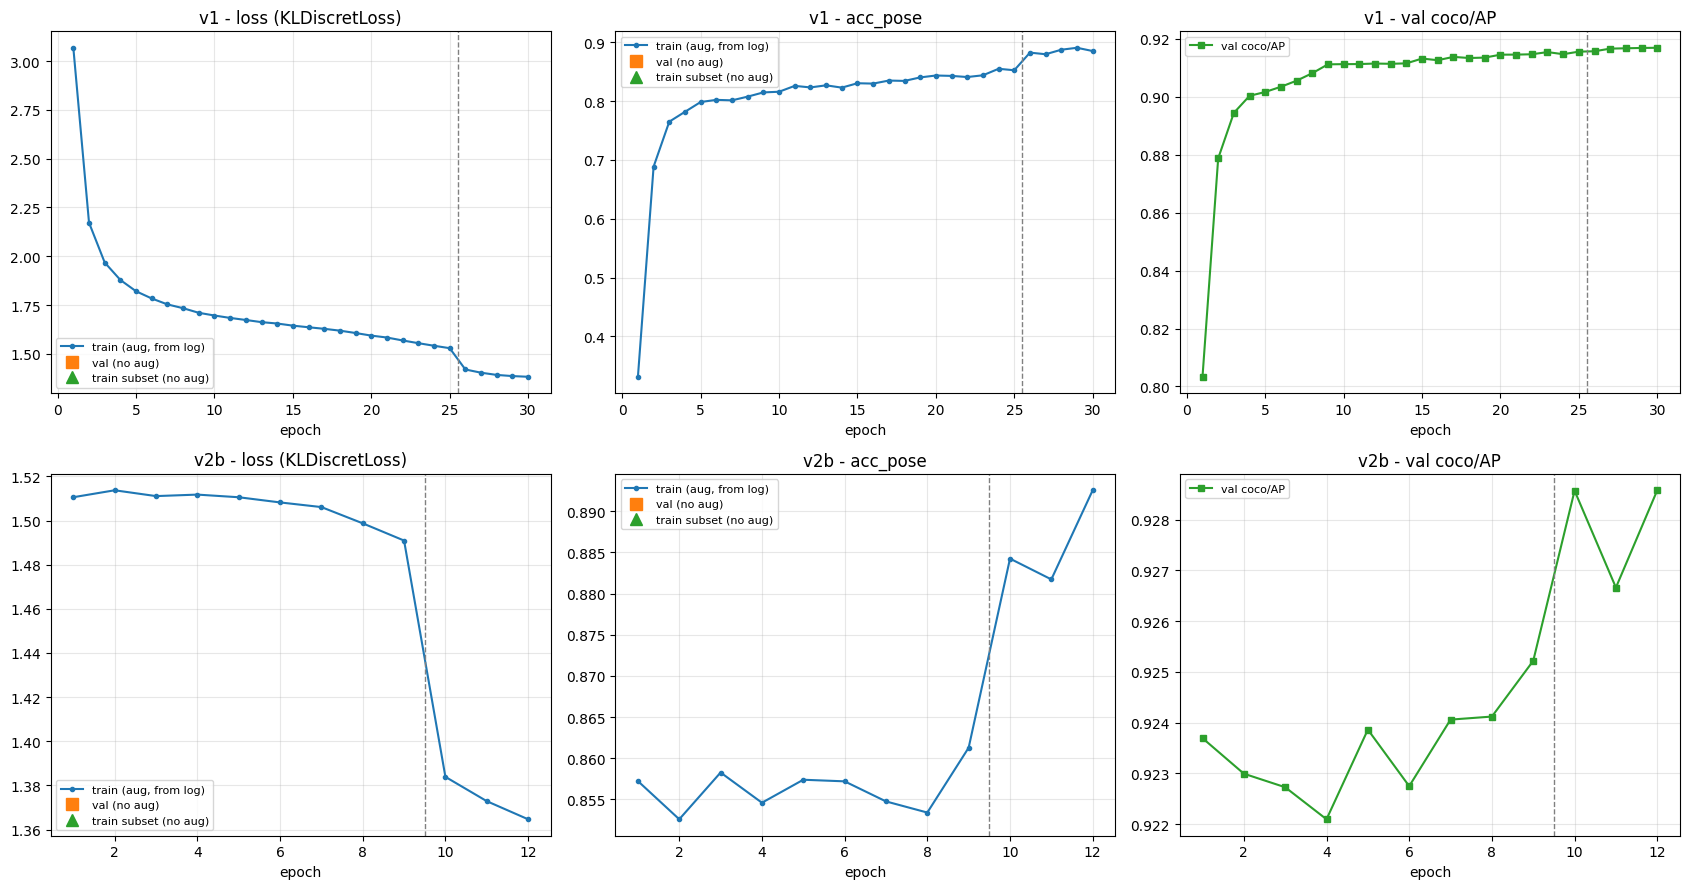


===== test (최종 에폭 = 배포 모델) =====
Empty DataFrame
Columns: [model, epoch, split, loss, acc_pose]
Index: []


In [44]:
import glob, re, json, os
import pandas as pd, matplotlib.pyplot as plt

TR = re.compile(r'Epoch\(train\)\s+\[(\d+)\]\[\s*(\d+)/(\d+)\].*?\slr: ([\d.e+-]+).*?\sloss: ([\d.]+).*?acc_pose: ([\d.]+)')
VA = re.compile(r'Epoch\(val\)\s+\[(\d+)\]\[\d+/\d+\]\s+coco/AP: ([\d.]+)\s+coco/AP \.5: ([\d.]+)\s+coco/AP \.75: ([\d.]+).*?coco/AR: ([\d.]+)')

def parse(wd):
    """work_dir 안의 실행별 로그(<timestamp>/<timestamp>.log)를 시간순으로 읽음. 재시작으로 겹친 구간은 나중 값 사용."""
    tr, va = {}, {}
    for f in sorted(glob.glob(f'{wd}/*/*.log')):
        for l in open(f, errors='ignore'):
            if (m := TR.search(l)): tr[(int(m[1]), int(m[2]))] = (float(m[4]), float(m[5]), float(m[6]))
            if (m := VA.search(l)): va[int(m[1])] = [float(x) for x in m.groups()[1:]]
    t = pd.DataFrame([(e, i, *v) for (e, i), v in tr.items()],
                     columns=['epoch', 'iter', 'lr', 'loss', 'acc_pose']).sort_values(['epoch', 'iter'])
    g = t.groupby('epoch').agg(lr=('lr', 'last'), train_loss=('loss', 'mean'), train_acc_pose=('acc_pose', 'mean'))
    v = pd.DataFrame.from_dict(va, orient='index', columns=['val_AP', 'val_AP50', 'val_AP75', 'val_AR'])
    return g.join(v, how='outer').rename_axis('epoch')

p = f'{DRIVE}/loss_last3.json'
L = pd.DataFrame(json.load(open(p))) if os.path.exists(p) else pd.DataFrame(columns=['model', 'epoch', 'split', 'loss', 'acc_pose'])
RUNS = {'v1': (f'{DRIVE}/work_dirs/drawing15_full', 25), 'v2b': (f'{DRIVE}/work_dirs/drawing15_v2b', 9)}   # (work_dir, stage2 전환 에폭)

fig, axes = plt.subplots(len(RUNS), 3, figsize=(17, 4.5 * len(RUNS)), squeeze=False)
for r, (name, (wd, sw)) in enumerate(RUNS.items()):
    t = parse(wd)
    for split in ['val', 'train_clean']:
        s = L[(L.model == name) & (L.split == split)].set_index('epoch')
        t[f'{split}_loss'], t[f'{split}_acc_pose'] = s.loss, s.acc_pose
    print(f'\n===== {name} =====\n' + t.round(4).to_string())
    t.to_csv(f'{DRIVE}/curves_{name}.csv')

    ax = axes[r]
    ax[0].plot(t.index, t.train_loss, 'o-', ms=3, label='train (aug, from log)')
    ax[0].plot(t.index, t.val_loss, 's', ms=8, label='val (no aug)')
    ax[0].plot(t.index, t.train_clean_loss, '^', ms=8, label='train subset (no aug)')
    ax[1].plot(t.index, t.train_acc_pose, 'o-', ms=3, label='train (aug, from log)')
    ax[1].plot(t.index, t.val_acc_pose, 's', ms=8, label='val (no aug)')
    ax[1].plot(t.index, t.train_clean_acc_pose, '^', ms=8, label='train subset (no aug)')
    ax[2].plot(t.index, t.val_AP, 's-', ms=4, color='C2', label='val coco/AP')
    for a, s in zip(ax, ['loss (KLDiscretLoss)', 'acc_pose', 'val coco/AP']):
        a.axvline(sw + 0.5, ls='--', c='gray', lw=1)       # stage2 (약한 augmentation) 시작
        a.set_title(f'{name} - {s}'); a.set_xlabel('epoch'); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{DRIVE}/curves_v1_v2b.png', dpi=150); plt.show()

print('\n===== test (최종 에폭 = 배포 모델) =====')
print(L[L.split == 'test'].to_string(index=False))